In [ ]:
# to reuse all_scores
#data = np.load("results/adbench/ensemble/train_seed=0/SomeDataset/semi/all_scores_seed0.npz")
#all_scores = data['all_scores']  # shape: (num_models, num_samples)
#labels = data['labels']
#
## Then you can do:
#max_score = np.max(all_scores, axis=0)
#min_score = np.min(all_scores, axis=0)
#median_score = np.median(all_scores, axis=0)

# Check for the way of combining predictions in ensemble_4

In [27]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from adbench.myutils import Utils
import sklearn.metrics as skm

In [62]:
ensemble_dir = "../results/adbench/ensemble_5/train_seed=0"

In [63]:
def low_density_anomalies(test_log_probs, num_anomalies):
    """ Helper function for the F1-score, selects the num_anomalies lowest values of test_log_prob
    """
    anomaly_indices = np.argpartition(test_log_probs, num_anomalies - 1)[:num_anomalies]
    preds = np.zeros(len(test_log_probs))
    preds[anomaly_indices] = 1
    return preds

In [64]:
seed = 0
utils = Utils()  # utils function
utils.set_seed(seed)

### 1. For the situation that we compute the ensemble `average score per sample`

In [74]:
average_ensemble_aucroc_scores = []
average_ensemble_aucpr_scores = []
average_ensemble_f1_scores = []
datasets_name = []
average_ensemble_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble average score per sample
        avg_score = np.mean(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-avg_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(avg_score))
        avg_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=avg_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        average_ensemble_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        average_ensemble_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        average_ensemble_f1_scores.append(f1)

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        time_instance = df['time-per-inst'].values[0]
        average_ensemble_time_per_instance.append(time_instance)


# compute average scores of all datasets
average_ensemble_avg_aucroc = round(sum(average_ensemble_aucroc_scores) / len(average_ensemble_aucroc_scores), 4)
average_ensemble_avg_aucpr = round(sum(average_ensemble_aucpr_scores) / len(average_ensemble_aucpr_scores), 4)
average_ensemble_avg_f1 = round(sum(average_ensemble_f1_scores) / len(average_ensemble_f1_scores), 4)
average_ensemble_time_per_instance_avg = sum(average_ensemble_time_per_instance) / len(average_ensemble_time_per_instance)

print(f"number of datasets: {len(average_ensemble_aucroc_scores)}")
print(f"Average aucroc: {average_ensemble_avg_aucroc}")
print(f"Average aucpr: {average_ensemble_avg_aucpr}")
print(f"Average f1: {average_ensemble_avg_f1}")
print(f"Inference time per instance: {average_ensemble_time_per_instance_avg}")

number of datasets: 121
Average aucroc: 0.7696
Average aucpr: 0.4884
Average f1: 0.4773
Inference time per instance: 0.032479155762073865


In [75]:
# create data
number_base_models = [6 for i in range(0, len(datasets_name))]
average_dict = {'#base_models': number_base_models, 'datasets_name': datasets_name, 'aucroc': average_ensemble_aucroc_scores, 'aucpr':average_ensemble_aucpr_scores, 'f1': average_ensemble_f1_scores}
average_df = pd.DataFrame(average_dict)
average_df

,#base_models,datasets_name,aucroc,aucpr,f1
0,6,23_mammography,0.808058,0.428500,0.415385
1,6,SVHN_5,0.627586,0.173830,0.185083
2,6,40_vowels,0.857923,0.404880,0.360000
3,6,MVTec-AD_tile,0.900934,0.898991,0.809322
4,6,26_optdigits,0.916242,0.374530,0.406667
...,...,...,...,...,...
116,6,CIFAR10_0,0.741417,0.251894,0.281369
117,6,SVHN_9,0.568264,0.129317,0.159184
118,6,CIFAR10_5,0.587720,0.124051,0.136882
119,6,45_wine,1.000000,1.000000,1.000000


/tmp/ipykernel_235331/2113949794.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=average_df, x='#base_models', y='aucroc', palette="Set2", legend='auto', width=0.5)


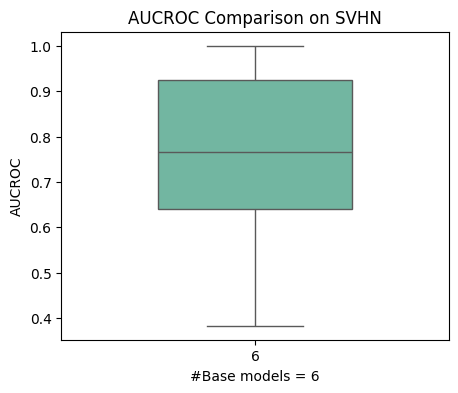

In [76]:
plt.figure(figsize=(5, 4))
#sns.boxplot(data=SVHN_melted, x='model', y='aucroc')
sns.boxplot(data=average_df, x='#base_models', y='aucroc', palette="Set2", legend='auto', width=0.5)
#sns.stripplot(data=average_df, x='model', y='aucroc', color='black', alpha=0.5)

plt.title('AUCROC Comparison on SVHN')
plt.xlabel('#Base models = 6')
plt.ylabel('AUCROC')

plt.show()
#plt.savefig('data_priors_impact.png', dpi=300, bbox_inches='tight')

### 2. For the situation that we compute the ensemble `max score per sample`

In [77]:
max_ensemble_aucroc_scores = []
max_ensemble_aucpr_scores = []
max_ensemble_f1_scores = []
datasets_name = []
max_ensemble_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']
        
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble max score per sample
        max_score = np.max(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-max_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(max_score))
        max_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=max_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        max_ensemble_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        max_ensemble_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        max_ensemble_f1_scores.append(f1)

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        time_instance = df['time-per-inst'].values[0]
        max_ensemble_time_per_instance.append(time_instance)


# compute average scores of all datasets
max_ensemble_avg_aucroc = round(sum(max_ensemble_aucroc_scores) / len(max_ensemble_aucroc_scores), 4)
max_ensemble_avg_aucpr = round(sum(max_ensemble_aucpr_scores) / len(max_ensemble_aucpr_scores), 4)
max_ensemble_avg_f1 = round(sum(max_ensemble_f1_scores) / len(max_ensemble_f1_scores), 4)
max_ensemble_time_per_instance_avg = sum(max_ensemble_time_per_instance) / len(max_ensemble_time_per_instance)

print(f"number of datasets: {len(max_ensemble_aucroc_scores)}")
print(f"Average aucroc: {max_ensemble_avg_aucroc}")
print(f"Average aucpr: {max_ensemble_avg_aucpr}")
print(f"Average f1: {max_ensemble_avg_f1}")
print(f"Inference time per instance: {max_ensemble_time_per_instance_avg}")

number of datasets: 121
Average aucroc: 0.7507
Average aucpr: 0.4708
Average f1: 0.4621
Inference time per instance: 0.032479155762073865


### 3. For the situation that we compute the ensemble `min score per sample`

In [78]:
min_ensemble_aucroc_scores = []
min_ensemble_aucpr_scores = []
min_ensemble_f1_scores = []
datasets_name = []
min_ensemble_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble min score per sample
        min_score = np.min(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-min_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(min_score))
        min_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=min_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        min_ensemble_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        min_ensemble_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        min_ensemble_f1_scores.append(f1)

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        time_instance = df['time-per-inst'].values[0]
        min_ensemble_time_per_instance.append(time_instance)

# compute average scores of all datasets
min_ensemble_avg_aucroc = round(sum(min_ensemble_aucroc_scores) / len(min_ensemble_aucroc_scores), 4)
min_ensemble_avg_aucpr = round(sum(min_ensemble_aucpr_scores) / len(min_ensemble_aucpr_scores), 4)
min_ensemble_avg_f1 = round(sum(min_ensemble_f1_scores) / len(min_ensemble_f1_scores), 4)
min_ensemble_time_per_instance_avg = sum(min_ensemble_time_per_instance) / len(min_ensemble_time_per_instance)

print(f"number of datasets: {len(min_ensemble_aucroc_scores)}")
print(f"Average aucroc: {min_ensemble_avg_aucroc}")
print(f"Average aucpr: {min_ensemble_avg_aucpr}")
print(f"Average f1: {min_ensemble_avg_f1}")
print(f"Inference time per instance: {min_ensemble_time_per_instance_avg}")

number of datasets: 121
Average aucroc: 0.7525
Average aucpr: 0.4628
Average f1: 0.4518
Inference time per instance: 0.032479155762073865


### 4. For the situation that we compute the ensemble `meam square score per sample`

In [79]:
ensemble_aucroc_scores = []
ensemble_aucpr_scores = []
ensemble_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # compute the ensemble mean square score per sample
        avg_score = np.mean(all_scores**2, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-avg_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(avg_score))
        avg_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=avg_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        ensemble_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        ensemble_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        ensemble_f1_scores.append(f1)

# compute average scores of all datasets
ensemble_avg_aucroc = round(sum(ensemble_aucroc_scores) / len(ensemble_aucroc_scores), 4)
ensemble_avg_aucpr = round(sum(ensemble_aucpr_scores) / len(ensemble_aucpr_scores), 4)
ensemble_avg_f1 = round(sum(ensemble_f1_scores) / len(ensemble_f1_scores), 4)

print(f"number of datasets: {len(ensemble_aucroc_scores)}")
print(f"Average aucroc: {ensemble_avg_aucroc}")
print(f"Average aucpr: {ensemble_avg_aucpr}")
print(f"Average f1: {ensemble_avg_f1}")

number of datasets: 121
Average aucroc: 0.7637
Average aucpr: 0.484
Average f1: 0.4729


### Visualization

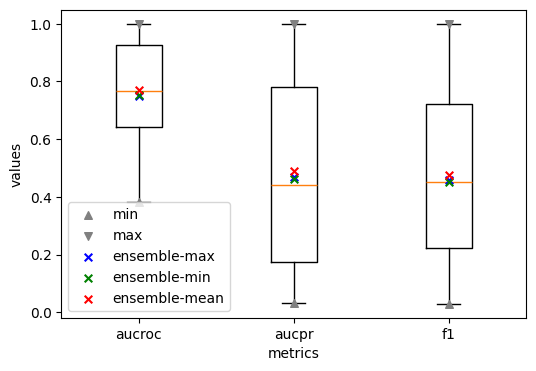

In [ ]:
metrics = [average_df['aucroc'], average_df['aucpr'], average_df['f1']]
positions = [1, 2, 3]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(metrics)


ensemble_mean = [average_ensemble_avg_aucroc, average_ensemble_avg_aucpr, average_ensemble_avg_f1]
ensemble_max = [max_ensemble_avg_aucroc, max_ensemble_avg_aucpr, max_ensemble_avg_f1]
ensemble_min = [min_ensemble_avg_aucroc, min_ensemble_avg_aucpr, min_ensemble_avg_f1]


# add markers
for x, arr, me, ma, mi in zip(positions, metrics, ensemble_mean, ensemble_max, ensemble_min):
    # mean
    ax.scatter(x, np.min(arr), marker="^", color="gray", s=30, zorder=3, label="min" if x == 1 else "")
    ax.scatter(x, np.max(arr), marker="v", color="gray", s=30, zorder=3, label="max" if x == 1 else "")
    ax.scatter(x, ma, marker="x", color="blue", s=30, zorder=3, label="ensemble-max" if x == 1 else "")
    ax.scatter(x, mi, marker="x", color="green", s=30, zorder=3, label="ensemble-min" if x == 1 else "")
    ax.scatter(x, me, marker="x", color="red", s=30, zorder=3, label="ensemble-mean" if x == 1 else "")

ax.set_xticklabels(['aucroc', 'aucpr', 'f1'])
plt.xlabel('metrics')
plt.ylabel('values')
ax.legend()
#plt.savefig('compare_combination_functions.png', dpi=300, bbox_inches='tight')
plt.show()